# 82 - Visualizar e interpretar clusters TF-IDF + DBSCAN

Este notebook inspeciona os assignments salvos pelo notebook 72. Ele resume os grupos, mostra os maiores clusters, exemplos de descricoes e termos distintivos ponderados pela frequencia. O rótulo `-1` representa ruido do DBSCAN.

Os arquivos de assignments nao incluem a matriz TF-IDF; portanto, as figuras mostram contagens e perfis textuais, sem representar distancias ou posicoes no espaco TF-IDF. Nenhum dado ou modelo e alterado e nenhuma saida e gravada. Execute as celulas em ordem.

## 1. Configuracoes

Escolha uma execucao existente. `RUN_INDEX = 0` seleciona a mais recente. Os clusters destacados sao definidos automaticamente pelos maiores grupos sem ruido; ajuste `CLUSTERS_TO_INSPECT` para outro recorte.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "notebooks" / "reports" / "tfidf_dbscan").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Nao encontrei notebooks/reports/tfidf_dbscan na raiz do repositorio.")
REPORTS_DIR = PROJECT_ROOT / "notebooks" / "reports" / "tfidf_dbscan"
RUN_INDEX = 0
TOP_N_CLUSTERS_IN_PLOT = 25  # Inclui o ruido, se presente.
CLUSTERS_TO_INSPECT = None  # None seleciona os tres maiores clusters sem ruido.
TOP_N_DESCRIPTIONS = 12
TOP_N_TERMS = 12
pd.set_option("display.max_colwidth", 140)

## 2. Funcoes da analise

A frequencia agrega quantos itens cada descricao representa. Os perfis lexicais contam tokens com esse peso e comparam a participacao do termo no cluster com a participacao nos demais clusters sem ruido.

In [2]:
def load_assignments(path):
    """Carrega assignments e valida as colunas necessarias para a inspecao."""
    frame = pd.read_csv(path)
    required = {"descricao_normalizada", "frequencia", "cluster", "ruido"}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"Colunas ausentes no arquivo de assignments: {sorted(missing)}")
    frame = frame.copy()
    frame["descricao_normalizada"] = frame["descricao_normalizada"].fillna("").astype(str)
    frame["frequencia"] = pd.to_numeric(frame["frequencia"], errors="raise")
    frame["cluster"] = pd.to_numeric(frame["cluster"], errors="raise").astype(int)
    frame["ruido"] = frame["ruido"].astype(str).str.lower().map({"true": True, "false": False})
    if frame["ruido"].isna().any():
        raise ValueError("A coluna 'ruido' contem valores diferentes de true/false.")
    if not frame["ruido"].equals(frame["cluster"].eq(-1)):
        raise ValueError("Os valores de 'ruido' nao correspondem ao rotulo -1.")
    return frame


def summarize_assignments(frame):
    """Resume descricoes unicas, frequencia e participacao por grupo."""
    summary = (
        frame.groupby("cluster", as_index=False)
        .agg(descricoes_unicas=("descricao_normalizada", "size"), frequencia_total=("frequencia", "sum"))
        .sort_values("descricoes_unicas", ascending=False)
    )
    summary["participacao_descricoes_pct"] = 100 * summary["descricoes_unicas"] / len(frame)
    summary["participacao_frequencia_pct"] = 100 * summary["frequencia_total"] / frame["frequencia"].sum()
    return summary


def weighted_term_profile(frame, cluster_id, top_n):
    """Retorna termos frequentes e seu lift contra os demais clusters sem ruido."""
    stopwords = {"a", "as", "ao", "com", "de", "da", "das", "do", "dos", "e", "em",
                 "para", "por", "sem", "um", "uma", "kg", "g", "gr", "lt", "l", "ml", "un", "und", "pct"}
    non_noise = frame.loc[frame["cluster"] != -1]
    inside = non_noise.loc[non_noise["cluster"] == cluster_id]
    outside = non_noise.loc[non_noise["cluster"] != cluster_id]

    def counts(rows):
        result = {}
        for description, frequency in zip(rows["descricao_normalizada"], rows["frequencia"]):
            for token in re.findall(r"[a-z0-9]+", description.lower()):
                if len(token) > 1 and token not in stopwords:
                    result[token] = result.get(token, 0) + int(frequency)
        return pd.Series(result, dtype="float64")

    inside_counts, outside_counts = counts(inside), counts(outside)
    inside_share = inside_counts / max(inside_counts.sum(), 1)
    outside_share = outside_counts / max(outside_counts.sum(), 1)
    profile = pd.DataFrame({"ocorrencias_ponderadas": inside_counts})
    profile["lift_vs_outros_clusters"] = (inside_share + 1e-9) / (outside_share.reindex(profile.index, fill_value=0) + 1e-9)
    return profile.sort_values(["lift_vs_outros_clusters", "ocorrencias_ponderadas"], ascending=False).head(top_n).reset_index(names="termo")


def plot_cluster_sizes(summary, top_n):
    """Compara os maiores grupos e o ruido sem sobrecarregar o grafico."""
    shown = summary.loc[summary["cluster"] != -1].nlargest(top_n, "descricoes_unicas")
    noise = summary.loc[summary["cluster"] == -1]
    shown = pd.concat([shown, noise]).sort_values("frequencia_total", ascending=True)
    labels = ["Ruido (-1)" if c == -1 else f"Cluster {c}" for c in shown["cluster"]]
    fig, axes = plt.subplots(1, 2, figsize=(15, max(5, len(shown) * 0.28)))
    axes[0].barh(labels, shown["descricoes_unicas"], color="#4C78A8")
    axes[0].set_title("Descricoes unicas"); axes[0].set_xlabel("Quantidade")
    axes[1].barh(labels, shown["frequencia_total"], color="#F58518")
    axes[1].set_title("Frequencia total (itens)"); axes[1].set_xlabel("Soma da frequencia")
    fig.suptitle(f"Maiores {top_n} clusters e ruido"); fig.tight_layout(); plt.show()


def plot_top_descriptions(frame, cluster_ids, top_n):
    """Mostra as descricoes de maior frequencia nos clusters selecionados."""
    fig, axes = plt.subplots(len(cluster_ids), 1, figsize=(13, 3.8 * len(cluster_ids)))
    if len(cluster_ids) == 1:
        axes = [axes]
    for ax, cluster_id in zip(axes, cluster_ids):
        rows = frame.loc[frame["cluster"] == cluster_id].nlargest(top_n, "frequencia").sort_values("frequencia")
        ax.barh(rows["descricao_normalizada"], rows["frequencia"], color="#54A24B")
        ax.set_title(f"Cluster {cluster_id}: descricoes mais frequentes"); ax.set_xlabel("Frequencia")
        ax.tick_params(axis="y", labelsize=8)
    fig.tight_layout(); plt.show()

## 3. Selecionar execucao e carregar os assignments

As execucoes sao ordenadas pela data de modificacao dos arquivos. Confira o periodo e os parametros no resumo antes de interpretar os clusters.

In [3]:
run_dirs = sorted(
    [path for path in REPORTS_DIR.iterdir() if path.is_dir() and (path / "assignments.csv").exists()],
    key=lambda path: path.stat().st_mtime, reverse=True,
)
if not run_dirs:
    raise FileNotFoundError(f"Nenhum assignments.csv encontrado em {REPORTS_DIR}. Execute o notebook 72 primeiro.")
if not 0 <= RUN_INDEX < len(run_dirs):
    raise IndexError(f"RUN_INDEX deve estar entre 0 e {len(run_dirs) - 1}.")
runs = pd.DataFrame({"indice": range(len(run_dirs)), "execucao": [p.name for p in run_dirs]})
display(runs)
RUN_DIR = run_dirs[RUN_INDEX]
assignments = load_assignments(RUN_DIR / "assignments.csv")
summary = summarize_assignments(assignments)
metadata_path = RUN_DIR / "run.json"
metadata = pd.read_json(metadata_path, typ="series") if metadata_path.exists() else None
print(f"Execucao: {RUN_DIR.name}")
print(f"Descricoes: {len(assignments):,} | frequencia total: {assignments['frequencia'].sum():,}")
print(f"Clusters sem ruido: {assignments.loc[assignments['cluster'] != -1, 'cluster'].nunique():,}")
print(f"Ruido: {(assignments['cluster'] == -1).sum():,} descricoes ({(assignments['cluster'] == -1).mean():.1%})")
if metadata is not None:
    display(metadata.to_frame("valor"))
display(summary.head(15))

,indice,execucao
0,0,202501-202512_20261013T035239Z
1,1,202501-202504_20261011T104017Z
2,2,202501-202504_20261011T101235Z
3,3,202501-202504_20261011T101150Z


Execucao: 202501-202512_20261013T035239Z
Descricoes: 257,879 | frequencia total: 1,238,688
Clusters sem ruido: 1,413
Ruido: 253,048 descricoes (98.1%)


,valor
dataset_name,2025_NCMs-sem-duplicatas
period,202501-202512
dataset_path,c:\Users\samue\Scripts\Nofis-Classifier\data\processed\2025_NCMs-sem-duplicatas\2025_NCMs-sem-duplicatas-202501-202512.parquet
max_descriptions,None
sample_seeds,[42]
analyzer_configs,"{'char_wb_3_5': {'analyzer': 'char_wb', 'ngram_range': [3, 5]}, 'word_1_2': {'analyzer': 'word', 'ngram_range': [1, 2]}}"
min_df,10
max_features,100000
selected_run_id,seed42_word_1_2_eps0.01_min_samples100
eps_values,"[0.01, 0.1, 0.30000000000000004, 0.5]"


,cluster,descricoes_unicas,frequencia_total,participacao_descricoes_pct,participacao_frequencia_pct
0,-1,253048,794933,98.126641,64.175402
1346,1345,530,530,0.205523,0.042787
8,7,312,1766,0.120987,0.142570
13,12,102,498,0.039553,0.040204
24,23,88,100,0.034125,0.008073
11,10,42,121,0.016287,0.009768
354,353,39,350,0.015123,0.028256
32,31,37,245,0.014348,0.019779
356,355,31,329,0.012021,0.026560
17,16,30,2422,0.011633,0.195529


## 4. Distribuicao dos clusters

O grafico compara os clusters de maior tamanho e inclui o ruido. A tabela abaixo contem todos os rótulos; ajuste `TOP_N_CLUSTERS_IN_PLOT` nas configuracoes para ampliar ou reduzir o recorte do grafico.

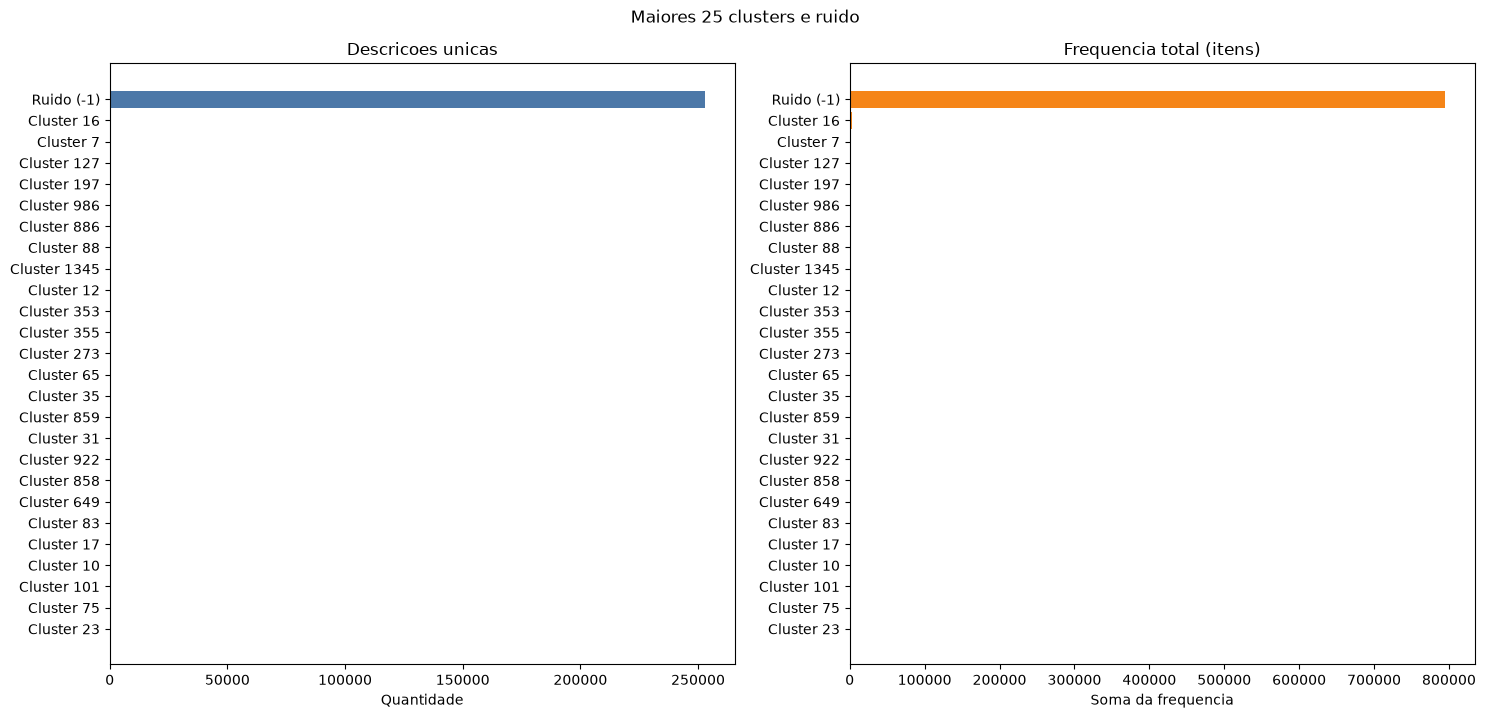

,cluster,descricoes_unicas,frequencia_total,participacao_descricoes_pct,participacao_frequencia_pct
0,-1,253048,794933,98.126641,64.175402
1346,1345,530,530,0.205523,0.042787
8,7,312,1766,0.120987,0.142570
13,12,102,498,0.039553,0.040204
24,23,88,100,0.034125,0.008073
...,...,...,...,...,...
47,46,1,100,0.000388,0.008073
20,19,1,2272,0.000388,0.183420
27,26,1,134,0.000388,0.010818
1376,1375,1,121,0.000388,0.009768


In [4]:
plot_cluster_sizes(summary, TOP_N_CLUSTERS_IN_PLOT)
display(summary)

## 5. Exemplos mais frequentes

Por padrao, sao destacados os tres maiores clusters sem ruido. As frequencias indicam quantos itens agregados cada descricao representa.

Clusters em destaque: [1345, 7, 12]


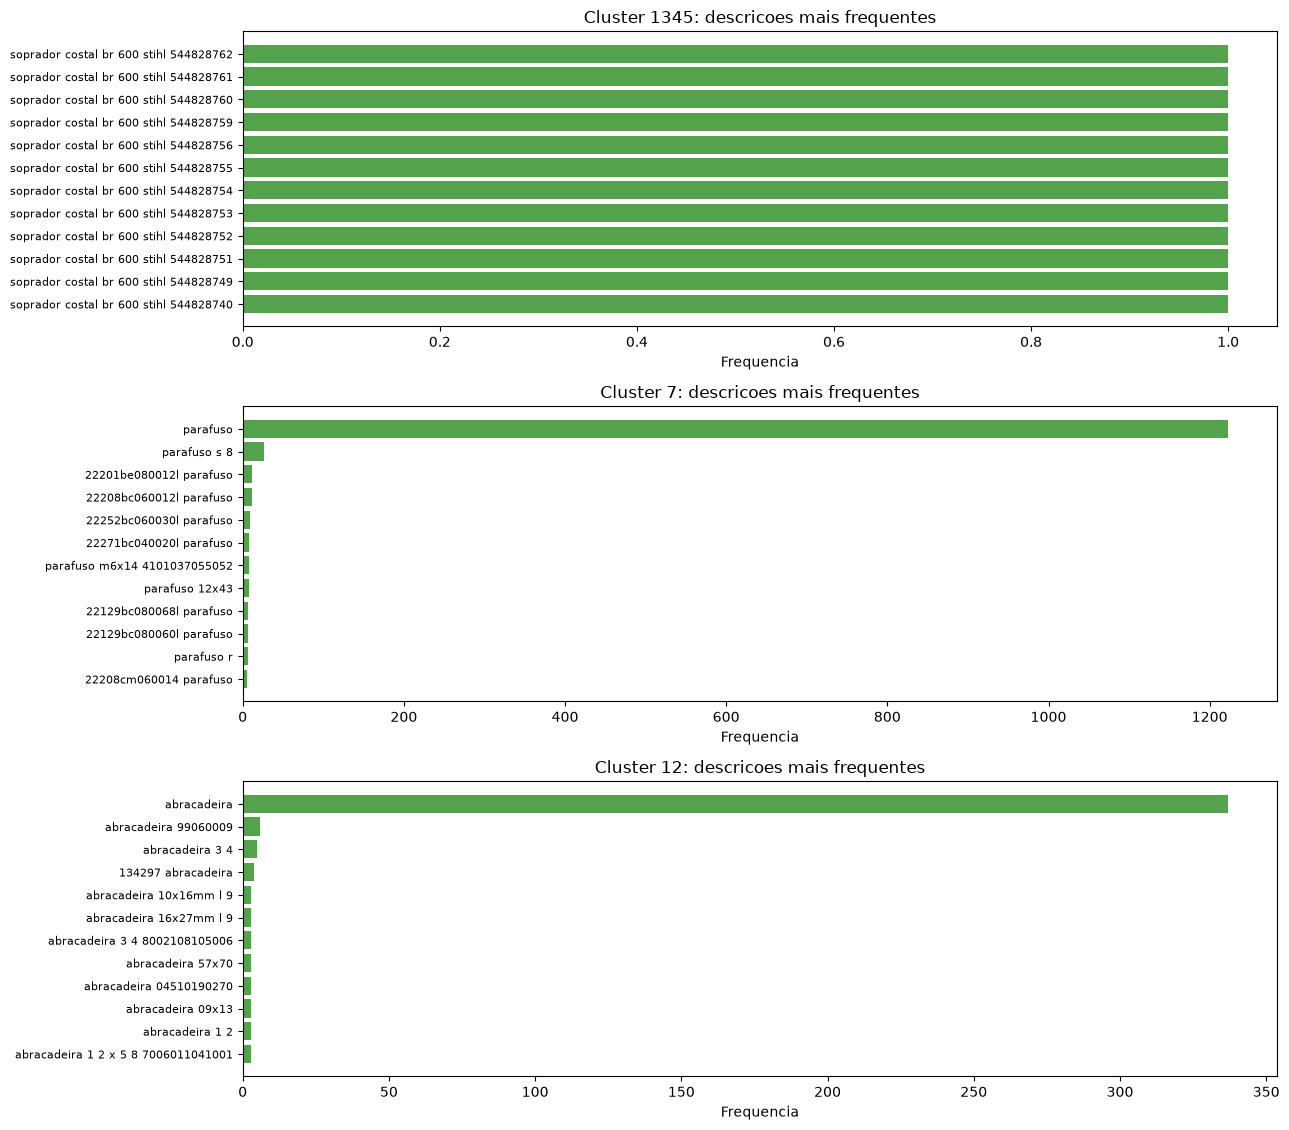

Cluster 1345: descricoes de maior frequencia


,descricao_normalizada,frequencia
0,soprador costal br 600 stihl 544828740,1
1,soprador costal br 600 stihl 544828749,1
2,soprador costal br 600 stihl 544828751,1
3,soprador costal br 600 stihl 544828752,1
4,soprador costal br 600 stihl 544828753,1
5,soprador costal br 600 stihl 544828754,1
6,soprador costal br 600 stihl 544828755,1
7,soprador costal br 600 stihl 544828756,1
8,soprador costal br 600 stihl 544828759,1
9,soprador costal br 600 stihl 544828760,1


Cluster 7: descricoes de maior frequencia


,descricao_normalizada,frequencia
0,parafuso,1223
1,parafuso s 8,27
2,22201be080012l parafuso,11
3,22208bc060012l parafuso,11
4,22252bc060030l parafuso,9
5,22271bc040020l parafuso,8
6,parafuso 12x43,8
7,parafuso m6x14 4101037055052,8
8,22129bc080060l parafuso,6
9,22129bc080068l parafuso,6


Cluster 12: descricoes de maior frequencia


,descricao_normalizada,frequencia
0,abracadeira,337
1,abracadeira 99060009,6
2,abracadeira 3 4,5
3,134297 abracadeira,4
4,abracadeira 04510190270,3
5,abracadeira 09x13,3
6,abracadeira 1 2,3
7,abracadeira 1 2 x 5 8 7006011041001,3
8,abracadeira 10x16mm l 9,3
9,abracadeira 16x27mm l 9,3


In [5]:
if CLUSTERS_TO_INSPECT is None:
    CLUSTERS_TO_INSPECT = summary.loc[summary["cluster"] != -1].head(3)["cluster"].astype(int).tolist()
unknown_clusters = set(CLUSTERS_TO_INSPECT).difference(assignments["cluster"].unique())
if unknown_clusters:
    raise ValueError(f"Clusters selecionados nao encontrados: {sorted(unknown_clusters)}")
print(f"Clusters em destaque: {CLUSTERS_TO_INSPECT}")
plot_top_descriptions(assignments, CLUSTERS_TO_INSPECT, TOP_N_DESCRIPTIONS)
for cluster_id in CLUSTERS_TO_INSPECT:
    print(f"Cluster {cluster_id}: descricoes de maior frequencia")
    display(assignments.loc[assignments["cluster"] == cluster_id].nlargest(TOP_N_DESCRIPTIONS, "frequencia")[
        ["descricao_normalizada", "frequencia"]].reset_index(drop=True))

## 6. Termos distintivos e interpretacao

O lift e uma pista exploratoria: termos raros ou descricoes curtas podem produzir valores altos. Leia o perfil junto com as descricoes completas; os clusters nao sao categorias validadas.

In [6]:
for cluster_id in CLUSTERS_TO_INSPECT:
    print(f"Cluster {cluster_id}: termos com maior lift lexical")
    display(weighted_term_profile(assignments, cluster_id, TOP_N_TERMS))

Cluster 1345: termos com maior lift lexical


,termo,ocorrencias_ponderadas,lift_vs_outros_clusters
0,soprador,530.0,1.666667e+08
1,costal,530.0,1.666667e+08
2,stihl,530.0,1.666667e+08
3,544828740,1.0,3.144664e+05
4,544828749,1.0,3.144664e+05
5,544828751,1.0,3.144664e+05
6,544828752,1.0,3.144664e+05
7,544828753,1.0,3.144664e+05
8,544828754,1.0,3.144664e+05
9,544828755,1.0,3.144664e+05


Cluster 7: termos com maior lift lexical


,termo,ocorrencias_ponderadas,lift_vs_outros_clusters
0,22201be080012l,11.0,4.662994e+06
1,22208bc060012l,11.0,4.662994e+06
2,22252bc060030l,9.0,3.815177e+06
3,husqv,9.0,3.815177e+06
4,pz6029fx,9.0,3.815177e+06
5,22271bc040020l,8.0,3.391268e+06
6,12x43,8.0,3.391268e+06
7,m6x14,8.0,3.391268e+06
8,4101037055052,8.0,3.391268e+06
9,22129bc080060l,6.0,2.543452e+06


Cluster 12: termos com maior lift lexical


,termo,ocorrencias_ponderadas,lift_vs_outros_clusters
0,supren,6.0,9.174313e+06
1,99060009,6.0,9.174313e+06
2,134297,4.0,6.116209e+06
3,04510190270,3.0,4.587157e+06
4,09x13,3.0,4.587157e+06
5,7006011041001,3.0,4.587157e+06
6,10x16mm,3.0,4.587157e+06
7,16x27mm,3.0,4.587157e+06
8,20x32,3.0,4.587157e+06
9,8002108105006,3.0,4.587157e+06


## 7. Limites da leitura

O TF-IDF e o DBSCAN foram ajustados sem NCM ou rotulos humanos. Silhouette, quantidade de ruido e inspecao de exemplos nao demonstram que os grupos correspondam a categorias corretas. Uma projecao espacial exigiria reconstruir a matriz TF-IDF com os mesmos dados e parametros do experimento; este notebook se concentra na inspecao dos assignments salvos.